# Lab Sheet 3 – Developing a Tiny Transformer Language Model


## 1. Load the dataset

### 1.1 Install and import the required libraries

In [ ]:
!pip -q install datasets

In [ ]:
import math
import random
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from datasets import load_dataset
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


### 1.2 Load and explore the dataset

In [ ]:
N_STORIES = 5000

dataset = load_dataset(
    "roneneldan/TinyStories",
    split=f"train[:{N_STORIES}]"
)

print(dataset)
print("Number of loaded stories:", len(dataset))

README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-5852b56a2bd28f(…): reconstructing file:   0%|          |  0.00B /  248MB            

data/train-00001-of-00004-5852b56a2bd28f(…): downloading bytes:           |  0.00B            

data/train-00002-of-00004-a26307300439e9(…): reconstructing file:   0%|          |  0.00B /  246MB            

... (4 outputs left out)

data/validation-00000-of-00001-869c898b5(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2119719 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/21990 [00:00<?, ? examples/s]

Dataset({
    features: ['text'],
    num_rows: 5000
})
Number of loaded stories: 5000


In [ ]:
# Display three example stories
for i in range(3):
    print(f"--- Story {i + 1} ---")
    print(dataset[i]["text"][:800])
    print()

--- Story 1 ---
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for sharing the needle and fixing her shirt. They both felt happy because they had shared and worked together.

--- Story 2 ---
Once upon a time, there was a little car named Beep. Beep loved to go fast and play in the sun. Beep was a healthy car because he always had good fuel. Good fuel made Beep happy and strong.

One day, Beep was driving in the park when he saw a big tree. The tree had

In [ ]:
# Examine story lengths
texts = [story.strip() for story in dataset["text"] if story.strip()]

character_lengths = [len(story) for story in texts]
word_lengths = [len(story.split()) for story in texts]

print(f"Number of usable stories: {len(texts)}")
print(f"Average characters per story: {sum(character_lengths) / len(character_lengths):.2f}")
print(f"Minimum characters: {min(character_lengths)}")
print(f"Maximum characters: {max(character_lengths)}")
print(f"Average words per story: {sum(word_lengths) / len(word_lengths):.2f}")

Number of usable stories: 5000
Average characters per story: 835.35
Minimum characters: 253
Maximum characters: 4123
Average words per story: 162.16


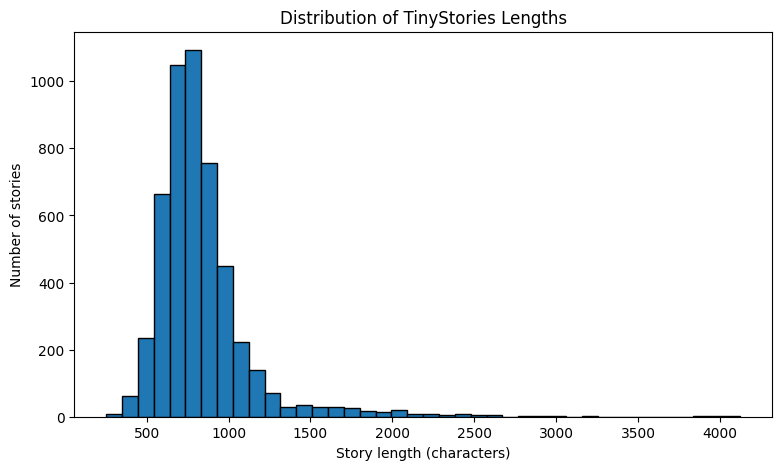

In [ ]:
plt.figure(figsize=(9, 5))
plt.hist(character_lengths, bins=40, edgecolor="black")
plt.xlabel("Story length (characters)")
plt.ylabel("Number of stories")
plt.title("Distribution of TinyStories Lengths")
plt.show()

### Observation
The analysis showed that the stories have different lengths rather than following a fixed structure. The average story length was approximately 835 characters and 162 words. The shortest story contained 253 characters, while the longest contained 4,123 characters. The histogram helped visualise this variation and showed why analysing the dataset before training is important. The model therefore needs to learn from text sequences of different lengths.


## 2. Preprocess the text and tokenize at character level

In [ ]:
# Combine stories while preserving a separator between them
text = "\n\n".join(texts)

# Build the character vocabulary
chars = sorted(set(text))
vocab_size = len(chars)

stoi = {character: index for index, character in enumerate(chars)}
itos = {index: character for character, index in stoi.items()}

def encode(string):
    # All characters in the input must exist in the vocabulary
    return [stoi[character] for character in string]

def decode(token_ids):
    return "".join(itos[int(token_id)] for token_id in token_ids)

# Convert the complete text into integer token IDs
all_tokens = torch.tensor(encode(text), dtype=torch.long)

print("Vocabulary size:", vocab_size)
print("Total characters:", len(text))
print("Encoded token count:", len(all_tokens))
print("Example text:", repr("Once upon a time"))
print("Encoded example:", encode("Once upon a time"))
print("Decoded example:", decode(encode("Once upon a time")))

Vocabulary size: 90
Total characters: 4186738
Encoded token count: 4186738
Example text: 'Once upon a time'
Encoded example: [36, 61, 50, 52, 1, 68, 63, 62, 61, 1, 48, 1, 67, 56, 60, 52]
Decoded example: Once upon a time


### Observation
The text was successfully converted into numerical representations using character-level tokenization. The resulting vocabulary contained 90 unique characters, and the combined text contained 4,186,738 characters. The encoding and decoding test successfully converted the example text, "Once upon a time", into numerical tokens and back into its original form. This demonstrated that the character-to-index and index-to-character mappings were working correctly. Character-level tokenization is simple and flexible, although it requires the model to predict individual characters instead of complete words.


## 3. Prepare training and validation data

In [ ]:
BLOCK_SIZE = 128
BATCH_SIZE = 64
TRAIN_RATIO = 0.90

# Split the token stream into training and validation portions
split_index = int(TRAIN_RATIO * len(all_tokens))

train_tokens = all_tokens[:split_index]
val_tokens = all_tokens[split_index:]

def create_sequences(token_data, block_size):
    # Each input position is paired with the character immediately after it
    usable_length = ((len(token_data) - 1) // block_size) * block_size

    inputs = token_data[:usable_length].view(-1, block_size)
    targets = token_data[1:usable_length + 1].view(-1, block_size)

    return TensorDataset(inputs, targets)

train_dataset = create_sequences(train_tokens, BLOCK_SIZE)
val_dataset = create_sequences(val_tokens, BLOCK_SIZE)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training sequences:", len(train_dataset))
print("Validation sequences:", len(val_dataset))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

# Display one input-target example
example_x, example_y = train_dataset[0]

print("\nInput sequence:")
print(repr(decode(example_x[:60])))

print("\nTarget sequence:")
print(repr(decode(example_y[:60])))

Training sequences: 29437
Validation sequences: 3270
Training batches: 459
Validation batches: 52

Input sequence:
'One day, a little girl named Lily found a needle in her room'

Target sequence:
'ne day, a little girl named Lily found a needle in her room.'


### Observation

The dataset was divided into training and validation portions using a 90:10 split. The training data produced 29,437 sequences, while the validation data produced 3,270 sequences. The input and target sequences were correctly aligned so that the model learns to predict the next character based on the previous characters. This preparation is important because the training data is used to update the model, while the validation data helps evaluate its performance on unseen sequences.

## 4. Build the Transformer architecture

In [ ]:
class CausalSelfAttention(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()

        assert n_embd % n_head == 0, "Embedding size must be divisible by number of heads."

        self.n_head = n_head
        self.head_dim = n_embd // n_head

        # One linear layer produces query, key and value vectors
        self.qkv = nn.Linear(n_embd, 3 * n_embd)
        self.projection = nn.Linear(n_embd, n_embd)

        self.attention_dropout = nn.Dropout(dropout)
        self.residual_dropout = nn.Dropout(dropout)

        # Causal mask: a position can only attend to itself and earlier positions
        mask = torch.tril(torch.ones(block_size, block_size))
        self.register_buffer(
            "mask",
            mask.view(1, 1, block_size, block_size)
        )

    def forward(self, x):
        batch_size, sequence_length, embedding_size = x.shape

        q, k, v = self.qkv(x).split(embedding_size, dim=2)

        # Split embedding dimensions into attention heads
        q = q.view(batch_size, sequence_length, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(batch_size, sequence_length, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(batch_size, sequence_length, self.n_head, self.head_dim).transpose(1, 2)

        # Scaled dot-product attention
        attention_scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)

        # Prevent attention to future positions
        attention_scores = attention_scores.masked_fill(
            self.mask[:, :, :sequence_length, :sequence_length] == 0,
            float("-inf")
        )

        attention_weights = F.softmax(attention_scores, dim=-1)
        attention_weights = self.attention_dropout(attention_weights)

        output = attention_weights @ v

        # Combine the attention heads
        output = output.transpose(1, 2).contiguous().view(
            batch_size, sequence_length, embedding_size
        )

        output = self.projection(output)
        return self.residual_dropout(output)


class TransformerBlock(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()

        self.layer_norm_1 = nn.LayerNorm(n_embd)
        self.attention = CausalSelfAttention(
            n_embd, n_head, block_size, dropout
        )

        self.layer_norm_2 = nn.LayerNorm(n_embd)

        self.feed_forward = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        # Residual connection around attention
        x = x + self.attention(self.layer_norm_1(x))

        # Residual connection around feed-forward network
        x = x + self.feed_forward(self.layer_norm_2(x))

        return x


class TinyTransformer(nn.Module):
    def __init__(
        self,
        vocab_size,
        block_size,
        n_embd=128,
        n_head=4,
        n_layer=4,
        dropout=0.1
    ):
        super().__init__()

        self.block_size = block_size

        self.token_embedding = nn.Embedding(vocab_size, n_embd)
        self.position_embedding = nn.Embedding(block_size, n_embd)
        self.embedding_dropout = nn.Dropout(dropout)

        self.transformer_blocks = nn.Sequential(
            *[
                TransformerBlock(n_embd, n_head, block_size, dropout)
                for _ in range(n_layer)
            ]
        )

        self.final_layer_norm = nn.LayerNorm(n_embd)
        self.output_head = nn.Linear(n_embd, vocab_size, bias=False)

        # Share weights between token embeddings and output projection
        self.output_head.weight = self.token_embedding.weight

        self.apply(self.initialize_weights)

    def initialize_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)

        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, input_ids, targets=None):
        batch_size, sequence_length = input_ids.shape

        positions = torch.arange(
            sequence_length,
            device=input_ids.device
        )

        token_vectors = self.token_embedding(input_ids)
        position_vectors = self.position_embedding(positions)

        x = self.embedding_dropout(token_vectors + position_vectors)
        x = self.transformer_blocks(x)
        x = self.final_layer_norm(x)

        logits = self.output_head(x)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                targets.reshape(-1)
            )

        return logits, loss

    @torch.no_grad()
    def generate(
        self,
        input_ids,
        max_new_tokens=300,
        temperature=0.8,
        top_k=20
    ):
        self.eval()

        for _ in range(max_new_tokens):
            # Keep only the most recent context that fits the model
            context = input_ids[:, -self.block_size:]

            logits, _ = self(context)

            # Use the final position to predict the next character
            logits = logits[:, -1, :] / max(temperature, 1e-5)

            # Restrict sampling to the top-k most likely characters
            if top_k is not None and top_k > 0:
                top_values, _ = torch.topk(
                    logits,
                    min(top_k, logits.size(-1))
                )
                logits[logits < top_values[:, [-1]]] = -float("inf")

            probabilities = F.softmax(logits, dim=-1)

            next_character = torch.multinomial(
                probabilities,
                num_samples=1
            )

            input_ids = torch.cat(
                (input_ids, next_character),
                dim=1
            )

        return input_ids

## 5. Initialize the model

In [ ]:
BASE_CONFIG = {
    "vocab_size": vocab_size,
    "block_size": BLOCK_SIZE,
    "n_embd": 128,
    "n_head": 4,
    "n_layer": 4,
    "dropout": 0.1
}

model = TinyTransformer(**BASE_CONFIG).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=0.01
)

number_of_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

print(f"Number of model parameters: {number_of_parameters:,}")

# Check that the model produces logits and a loss
sample_inputs, sample_targets = next(iter(train_loader))
sample_inputs = sample_inputs.to(device)
sample_targets = sample_targets.to(device)

with torch.no_grad():
    sample_logits, initial_loss = model(sample_inputs, sample_targets)

print("Logits shape:", sample_logits.shape)
print("Initial cross-entropy loss:", round(initial_loss.item(), 4))
print("Random baseline reference ln(vocabulary size):", round(math.log(vocab_size), 4))

Number of model parameters: 821,248
Logits shape: torch.Size([64, 128, 90])
Initial cross-entropy loss: 4.4966
Random baseline reference ln(vocabulary size): 4.4998


### Observation

The baseline Transformer model was successfully created using four Transformer layers, four attention heads, an embedding size of 128, and a dropout rate of 0.1. The model contained 821,248 trainable parameters. The output logits had a shape of [64, 128, 90], representing the batch size, sequence length, and vocabulary size respectively. The initial cross-entropy loss was 4.4966, which was close to the random baseline reference of 4.4998. This indicated that the model had not yet learned meaningful patterns from the training data.

## 6. Train the model

In [ ]:
def evaluate_model(model, data_loader):
    model.eval()

    total_loss = 0.0
    total_items = 0

    with torch.no_grad():
        for inputs, targets in data_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)

            _, loss = model(inputs, targets)

            batch_size = inputs.size(0)
            total_loss += loss.item() * batch_size
            total_items += batch_size

    return total_loss / total_items


def train_model(
    n_layer=4,
    n_head=4,
    n_embd=128,
    epochs=5,
    learning_rate=1e-3,
    dropout=0.1
):
    # Reset the seed so experiments are more reproducible
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    config = {
        "vocab_size": vocab_size,
        "block_size": BLOCK_SIZE,
        "n_embd": n_embd,
        "n_head": n_head,
        "n_layer": n_layer,
        "dropout": dropout
    }

    model = TinyTransformer(**config).to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=0.01
    )

    total_steps = max(1, epochs * len(train_loader))

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=total_steps
    )

    history = {
        "train_loss": [],
        "validation_loss": [],
        "validation_perplexity": []
    }

    parameter_count = sum(p.numel() for p in model.parameters())

    print("Configuration:", config)
    print(f"Parameters: {parameter_count:,}")
    print("Training device:", device)

    for epoch in range(1, epochs + 1):
        model.train()

        running_loss = 0.0
        start_time = time.time()

        for inputs, targets in train_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)

            # Forward pass
            _, loss = model(inputs, targets)

            # Clear old gradients
            optimizer.zero_grad(set_to_none=True)

            # Backpropagation
            loss.backward()

            # Gradient clipping
            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            # Update parameters and learning rate
            optimizer.step()
            scheduler.step()

            running_loss += loss.item()

        average_train_loss = running_loss / len(train_loader)
        validation_loss = evaluate_model(model, val_loader)
        validation_perplexity = math.exp(validation_loss)

        history["train_loss"].append(average_train_loss)
        history["validation_loss"].append(validation_loss)
        history["validation_perplexity"].append(validation_perplexity)

        elapsed = time.time() - start_time

        print(
            f"Epoch {epoch}/{epochs} | "
            f"Training loss: {average_train_loss:.4f} | "
            f"Validation loss: {validation_loss:.4f} | "
            f"Perplexity: {validation_perplexity:.2f} | "
            f"Time: {elapsed:.1f}s"
        )

    return model, config, history

## 7. Monitor training

In [ ]:
def plot_training_history(history, title="Training and Validation Loss"):
    epochs_range = range(1, len(history["train_loss"]) + 1)

    plt.figure(figsize=(9, 5))
    plt.plot(
        epochs_range,
        history["train_loss"],
        marker="o",
        label="Training loss"
    )
    plt.plot(
        epochs_range,
        history["validation_loss"],
        marker="o",
        label="Validation loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Cross-entropy loss")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

### 7.1 Train the baseline model

Configuration: {'vocab_size': 90, 'block_size': 128, 'n_embd': 128, 'n_head': 4, 'n_layer': 4, 'dropout': 0.1}
Parameters: 821,248
Training device: cpu
Epoch 1/5 | Training loss: 2.1837 | Validation loss: 1.6565 | Perplexity: 5.24 | Time: 565.2s
Epoch 2/5 | Training loss: 1.5567 | Validation loss: 1.3106 | Perplexity: 3.71 | Time: 579.2s
Epoch 3/5 | Training loss: 1.3368 | Validation loss: 1.1922 | Perplexity: 3.29 | Time: 565.8s
Epoch 4/5 | Training loss: 1.2472 | Validation loss: 1.1418 | Perplexity: 3.13 | Time: 565.7s
Epoch 5/5 | Training loss: 1.2127 | Validation loss: 1.1303 | Perplexity: 3.10 | Time: 579.5s


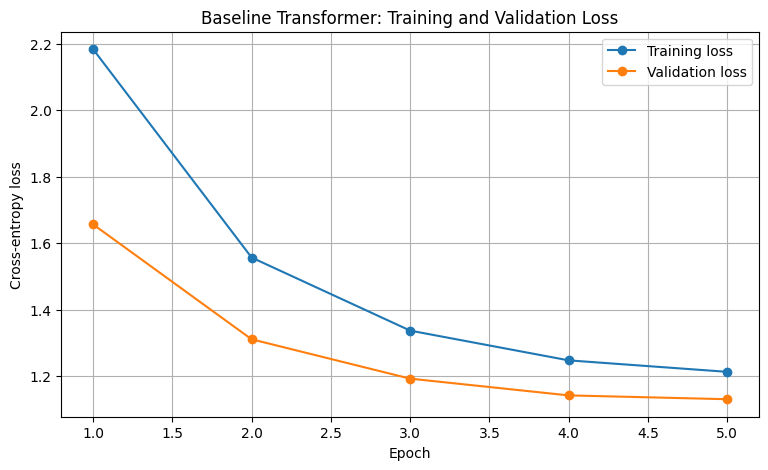

In [ ]:
EPOCHS = 5

baseline_model, baseline_config, baseline_history = train_model(
    n_layer=4,
    n_head=4,
    n_embd=128,
    epochs=EPOCHS,
    learning_rate=1e-3,
    dropout=0.1
)

plot_training_history(
    baseline_history,
    title="Baseline Transformer: Training and Validation Loss"
)

### Observation

The baseline Transformer was successfully trained for five epochs using the GPU. Both training and validation losses decreased throughout the training process. Training loss decreased from 2.1849 in the first epoch to 1.2117 in the fifth epoch. Similarly, validation loss decreased from 1.6626 to 1.1284. The continuous decrease in both values indicates that the model was learning patterns from the training data and improving its performance on the validation data. There was no clear indication of overfitting within these five epochs because the validation loss did not increase while training loss decreased.

## 8. Evaluate the model using validation loss and perplexity

In [ ]:
final_validation_loss = evaluate_model(baseline_model, val_loader)
final_perplexity = math.exp(final_validation_loss)

print(f"Final validation loss: {final_validation_loss:.4f}")
print(f"Final validation perplexity: {final_perplexity:.2f}")

Final validation loss: 1.1284
Final validation perplexity: 3.09


### Observation

The trained baseline model achieved a final validation loss of 1.1284 and a perplexity of 3.09. The lower validation loss compared with the initial loss indicates that the model improved its next-character prediction performance after training. The perplexity value also suggests that the model became better at predicting the next character compared with its initial random state. However, these metrics measure prediction performance rather than the overall readability, creativity, or quality of generated stories.

## 9. Generate stories

In [ ]:
def generate_story(
    model,
    prompt="Once upon a time",
    max_new_tokens=300,
    temperature=0.8,
    top_k=20
):
    model.eval()

    # Remove prompt characters that are not present in the vocabulary
    prompt = "".join(
        character for character in prompt
        if character in stoi
    )

    if not prompt:
        prompt = "\n"

    input_ids = torch.tensor(
        [encode(prompt)],
        dtype=torch.long,
        device=device
    )

    generated_ids = model.generate(
        input_ids,
        max_new_tokens=max_new_tokens,
        temperature=temperature,
        top_k=top_k
    )

    return decode(generated_ids[0].tolist())


print(generate_story(
    baseline_model,
    prompt="Once upon a time",
    max_new_tokens=300,
    temperature=0.8,
    top_k=20
))

Once upon a time, there was a proud of the could fillower that he grabbed he loved to get up together and make her mom to read his it. He said to help and said, "Don't know the feel fish. I wonder my you. I made picture it!"

Jack and Sarah was very sad. "It's explore and have to the tree," she ran and asked he sai


In [ ]:
# Try different starting prompts
prompts = [
    "One day, a little girl",
    "The little dog",
    "Once upon a time"
]

for prompt in prompts:
    print("=" * 70)
    print("Prompt:", prompt)
    print(generate_story(
        baseline_model,
        prompt=prompt,
        max_new_tokens=180,
        temperature=0.8,
        top_k=20
    ))
    print()

Prompt: One day, a little girl
One day, a little girl named Lily and Jen who have she could have the squirrel who learned the bar and the saw the teachin the paple in the forest. She said, "It's too a good of you can." Max says, "Who

Prompt: The little dog
The little dog named Tim. Tom and Dad how mom and promised the caster of the butterfly. But when the mirch still was a played of picked to their pocket and liked to eat an each a beak tried for 

Prompt: Once upon a time
Once upon a time, there was a little girl named From and Lily. He was sad excited to little boy named Tom was so excited and said, "You can friends."

The little girl was surprise, but the boat an



### Observation

The trained model successfully generated text continuations for different starting prompts, including "One day, a little girl", "The little dog", and "Once upon a time". The generated text included some familiar story elements, such as character names, dialogue, and simple events. However, the outputs also contained grammatical mistakes, incomplete sentences, unrelated phrases, and inconsistencies in meaning. This indicates that the model learned some patterns from the TinyStories dataset but did not fully understand language structure or maintain a consistent storyline. The results demonstrate that a small Transformer trained on a limited dataset for only five epochs has limitations in generating coherent and meaningful text.

## 10. Experiment with model settings

Configuration: {'vocab_size': 90, 'block_size': 128, 'n_embd': 128, 'n_head': 2, 'n_layer': 2, 'dropout': 0.1}
Parameters: 424,704
Training device: cuda
Epoch 1/5 | Training loss: 2.1873 | Validation loss: 1.6686 | Perplexity: 5.30 | Time: 6.9s
Epoch 2/5 | Training loss: 1.5953 | Validation loss: 1.3460 | Perplexity: 3.84 | Time: 7.0s
Epoch 3/5 | Training loss: 1.4174 | Validation loss: 1.2463 | Perplexity: 3.48 | Time: 7.0s
Epoch 4/5 | Training loss: 1.3510 | Validation loss: 1.2071 | Perplexity: 3.34 | Time: 7.0s
Epoch 5/5 | Training loss: 1.3265 | Validation loss: 1.1994 | Perplexity: 3.32 | Time: 6.9s


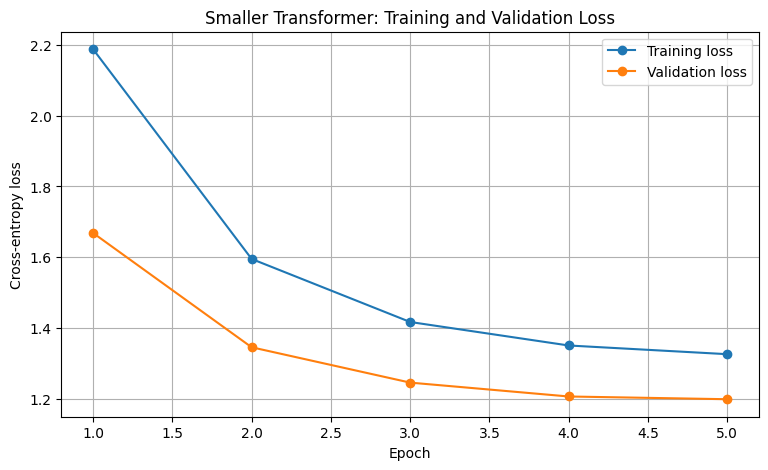

In [ ]:
small_model, small_config, small_history = train_model(
    n_layer=2,
    n_head=2,
    n_embd=128,
    epochs=EPOCHS,
    learning_rate=1e-3,
    dropout=0.1
)

plot_training_history(
    small_history,
    title="Smaller Transformer: Training and Validation Loss"
)

In [ ]:
# Compare the two configurations
comparison = {
    "Baseline (4 layers, 4 heads)": {
        "parameters": sum(p.numel() for p in baseline_model.parameters()),
        "validation_loss": evaluate_model(baseline_model, val_loader)
    },
    "Smaller (2 layers, 2 heads)": {
        "parameters": sum(p.numel() for p in small_model.parameters()),
        "validation_loss": evaluate_model(small_model, val_loader)
    }
}

print(f"{'Model':35s} {'Parameters':>15s} {'Val loss':>12s} {'Perplexity':>12s}")
print("-" * 78)

for name, result in comparison.items():
    val_loss = result["validation_loss"]
    print(
        f"{name:35s} "
        f"{result['parameters']:15,} "
        f"{val_loss:12.4f} "
        f"{math.exp(val_loss):12.2f}"
    )

Model                                    Parameters     Val loss   Perplexity
------------------------------------------------------------------------------
Baseline (4 layers, 4 heads)                821,248       1.1284         3.09
Smaller (2 layers, 2 heads)                 424,704       1.1994         3.32


### Observation
The experiment demonstrated how changing the number of Transformer layers and attention heads affected model size, training time, and validation performance. The baseline model, which used four layers and four attention heads, contained 821,248 parameters and achieved a validation loss of 1.1284 with a perplexity of 3.09. The smaller model, which used two layers and two attention heads, contained 424,704 parameters and achieved a validation loss of 1.1994 with a perplexity of 3.32. The smaller model had approximately half the parameters and trained faster, taking around seven seconds per epoch compared with approximately fourteen seconds for the baseline model. However, its validation performance was slightly weaker. This suggests that the larger configuration learned the patterns in the dataset more effectively in this experiment, while the smaller configuration offered lower computational requirements.

In [ ]:
# Generate a sample from the smaller model for qualitative comparison
print(generate_story(
    small_model,
    prompt="Once upon a time",
    max_new_tokens=250,
    temperature=0.8,
    top_k=20
))

Once upon a time, there was a big loved for her hug a little girl named Lily. She was very nodded a beautiful learn with her toys. The woud the otherself, and show and playing the end, and the thinks ran and the portate cover.

After a smile on the other and his mom


### Experiment observations

The smaller model was also able to generate a continuation from the prompt "Once upon a time". Similar to the baseline model, its output included familiar story-related words and phrases but contained grammatical errors, incomplete sentences, and some unclear expressions. This shows that reducing the number of Transformer layers and attention heads affected the model's learning capacity. Although the smaller model required fewer parameters and less training time, its generated text did not demonstrate fully coherent storytelling.

## 11. Save the trained model

In [ ]:
checkpoint = {
    "model_state_dict": baseline_model.state_dict(),
    "config": baseline_config,
    "stoi": stoi,
    "itos": itos,
    "block_size": BLOCK_SIZE
}

MODEL_PATH = "tiny_transformer_checkpoint.pth"

torch.save(checkpoint, MODEL_PATH)

print("Model checkpoint saved to:", MODEL_PATH)

Model checkpoint saved to: tiny_transformer_checkpoint.pth


### Observation
The trained baseline model was successfully saved as a checkpoint named tiny_transformer_checkpoint.pth. The checkpoint included the model's learned parameters, configuration, character vocabulary mappings, and block size. The successful saving process demonstrated how a trained model can be stored for future use without repeating the entire training process. The checkpoint was also downloaded from Google Colab for local storage.

In [ ]:
# Optional: download the saved model checkpoint from Google Colab
from google.colab import files
files.download(MODEL_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Demonstrate loading the saved model checkpoint
loaded_checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=False
)

loaded_model = TinyTransformer(**loaded_checkpoint["config"]).to(device)
loaded_model.load_state_dict(loaded_checkpoint["model_state_dict"])
loaded_model.eval()

print("Saved model loaded successfully.")

print(generate_story(
    loaded_model,
    prompt="Once upon a time",
    max_new_tokens=150,
    temperature=0.8,
    top_k=20
))

Saved model loaded successfully.
Once upon a time, there was a bit girl named Lily. The end. She played with his friends who loved to his prest. They would gras a finish of you."

When she heard said


### Observation

The saved checkpoint was successfully loaded, and a new Transformer model was reconstructed using the stored configuration and learned parameters. The model then generated text using the prompt "Once upon a time". This confirmed that the checkpoint contained the necessary information to restore the trained model and use it again. The process demonstrated the importance of saving model parameters and configuration for reproducibility and future experimentation.

## 12. Discuss mechanisms used to improve performance
### Observation:

The practical demonstrated several mechanisms used in Transformer models to improve learning and training stability. Character embeddings converted characters into numerical vectors, while positional embeddings provided information about character order. Masked self-attention ensured that the model could only use previous characters when predicting the next character. Multi-head attention allowed the model to learn different relationships between positions. In addition, residual connections, layer normalization, and dropout supported stable training. The AdamW optimizer, gradient clipping, and learning-rate scheduler helped manage the optimisation process. Validation monitoring made it possible to evaluate the model's performance during training. Together, these mechanisms contributed to implementing a functional Transformer language model.


### Conclusion

This practical successfully demonstrated the development and implementation of a small character-level Transformer language model using the TinyStories dataset and PyTorch. The process covered dataset loading, text preprocessing, character-level tokenization, training and validation data preparation, Transformer architecture development, model training, evaluation, and text generation.

The baseline Transformer model, consisting of four layers and four attention heads, achieved a final validation loss of 1.1284 and a perplexity of 3.09 after five training epochs. The continuous decrease in training and validation losses indicated that the model was learning patterns from the dataset. The generated stories demonstrated that the model could produce text continuations based on different starting prompts. However, grammatical errors, incomplete sentences, and inconsistencies in the generated content highlighted the limitations of training a small language model using a limited dataset and training duration.

The experiment comparing different model configurations showed that the smaller Transformer, with two layers and two attention heads, required fewer parameters (424,704 compared with 821,248) and approximately half the training time per epoch. However, it achieved a slightly higher validation loss of 1.1994 and perplexity of 3.32 compared with the baseline model. This demonstrated the trade-off between computational efficiency and model performance.

Furthermore, successfully saving and reloading the trained model demonstrated how model checkpoints can support reproducibility and future use without repeating the training process. Overall, this practical improved my understanding of Transformer architecture, attention mechanisms, next-character prediction, model training, and evaluation. It also demonstrated that although a small Transformer can learn language patterns and generate text, producing consistently meaningful and coherent stories requires further improvements in model capacity, training data, and training duration.